# T-Rex overview

Create T-Rex with its default control parameters, then simulate it in two ways:

- with tof: the chopper cascade alone, drawn as a time-distance diagram;
- with McStas: write the .instr file to `mcstas_input/TRex/` of the repository, print it, and plot
  the instrument with McStas's mcdisplay, seen from above and along the beam.

Then look at it in 3D. Nothing here is saved for the documentation, which makes its own files
with the scripts in `scripts/`.

In [6]:
from pathlib import Path
from unittest.mock import patch

import matplotlib.pyplot as plt

from mcdgs.instruments.trex.model import Params, TRex
from mcdgs.mcstas.builder import build_mcstas, default_input_dir
from mcdgs.tof.builder import build_tof

# the repository: the first folder up from here that holds pyproject.toml
WORK_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())

## Create the instrument

In [7]:
params = Params(
    t0_offset=0.0017,  # s, when the neutrons the choppers are phased to leave the moderator
    lambda0=2.0,  # Å, central wavelength
    rrm=18,  # repetition rate multiplication
    mode="FF",  # "FF" high flux, "RR" high resolution
)
trex = TRex(params=params)
print(trex)

TRex 'TRex'

Params:
param      value      unit    comment
---------  ---------  ------  -----------------------------------------------------------
t0_offset  0.0017     s       time added to choppers shifting to middle of the long pulse
lambda0    2          Å       central wavelength
rrm        18                 repetition rate multiplication factor
mode       FF                 FF = high flux, RR = high resolution
omega      0          deg     goniometer rotation about +Y
bender_in  False              True = bender in, False = bender out
b_rot      -0.397881  deg     rotation of the cold neutron bender

Instrument parameters (McStas):
name       value      unit    comment
---------  ---------  ------  -----------------------------------
bender_in  0                  bender in = 1, out = 0
b_rot      -0.397881  deg     rotation of the cold neutron bender
omega      0          deg     rotation of the goniometer about +Y
nu_bw1     14         Hz      rotation frequency of chopper bw1

## Create a TOF model

In [8]:
# the source, the six chopper disks and the monitor at the sample position; tof leaves out the
# guides and the bender
tof_model = build_tof(trex, neutrons=1_000_000, seed=1)
tof_model

Model:
  Source: Source:
  pulses=1, neutrons per pulse=1000000
  frequency=14.0 Hz
  facility='ess'
  distance=0.0 m
  Choppers:
    bw1: Chopper(name=bw1, distance=31.964021615206406 m, frequency=14.0 Hz, phase=90.0125787628733 deg, direction=ANTICLOCKWISE, cutouts=1)
    bw2: Chopper(name=bw2, distance=39.95500668523827 m, frequency=14.0 Hz, phase=110.37369797352756 deg, direction=ANTICLOCKWISE, cutouts=1)
    ps1: Chopper(name=ps1, distance=107.94959927562525 m, frequency=189.0 Hz, phase=3773.9414393275792 deg, direction=ANTICLOCKWISE, cutouts=4)
    ps2: Chopper(name=ps2, distance=108.04959859099564 m, frequency=189.0 Hz, phase=3887.381247979111 deg, direction=CLOCKWISE, cutouts=4)
    mc1: Chopper(name=mc1, distance=162.02685248580156 m, frequency=252.0 Hz, phase=7410.471950478918 deg, direction=ANTICLOCKWISE, cutouts=2)
    mc2: Chopper(name=mc2, distance=162.03685245517002 m, frequency=252.0 Hz, phase=7410.930591632457 deg, direction=ANTICLOCKWISE, cutouts=2)
  Detectors:
    s

In [9]:
tof_result = tof_model.run()
tof_result

Result:
  Source: 1 pulses, 1000000 neutrons per pulse.
  Choppers:
    bw1: visible=372795, blocked=627205
    bw2: visible=297411, blocked=75384
    ps1: visible=90820, blocked=206591
    ps2: visible=56798, blocked=34022
    mc1: visible=1892, blocked=54906
    mc2: visible=1857, blocked=35
  Detectors:
    sample_monitor: visible=1857

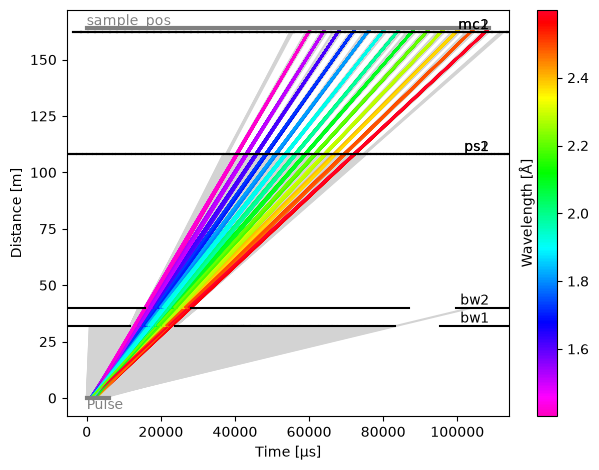

In [11]:
# the paths of the neutrons that reach the sample, colored by wavelength, and some of those the
# choppers stop
diagram = tof_result.plot(visible_rays=1000, blocked_rays=5000)

## Create McStas model

In [ ]:
mcstas_instr = build_mcstas(trex, input_path=default_input_dir(trex, WORK_DIR))
mcstas_instr.write_full_instrument()
mcstas_instr.show_instrument_file()

/********************************************************************************
* 
* McStas, neutron ray-tracing package
*         Copyright (C) 1997-2008, All rights reserved
*         Risoe National Laboratory, Roskilde, Denmark
*         Institut Laue Langevin, Grenoble, France
* 
* This file was written by McStasScript, which is a 
* python based McStas instrument generator written by 
* Mads Bertelsen in 2019 while employed at the 
* European Spallation Source Data Management and 
* Software Centre
* 
* Instrument: TRex
* 
* %Identification
* Written by: Python McStas Instrument Generator
* Date: 21:35:14 on November 03, 2026
* Origin: ESS DMSC
* %INSTRUMENT_SITE: Generated_instruments
* 
* !!Please write a short instrument description (1 line) here!!
* 
* %Description
* Please write a longer instrument description here!
* 
* 
* %Parameters
* bender_in: [unit] bender in = 1, out = 0
* b_rot: [unit] rotation of the cold neutron bender
* omega: [unit] rotation of the goniometer ab

## Plot the layout of the instrument

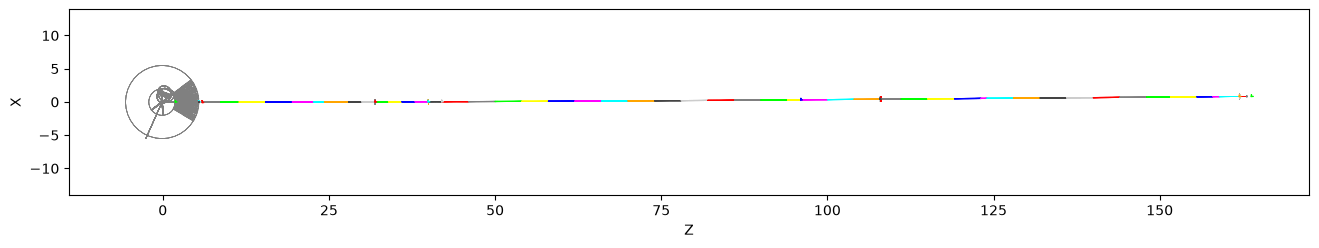

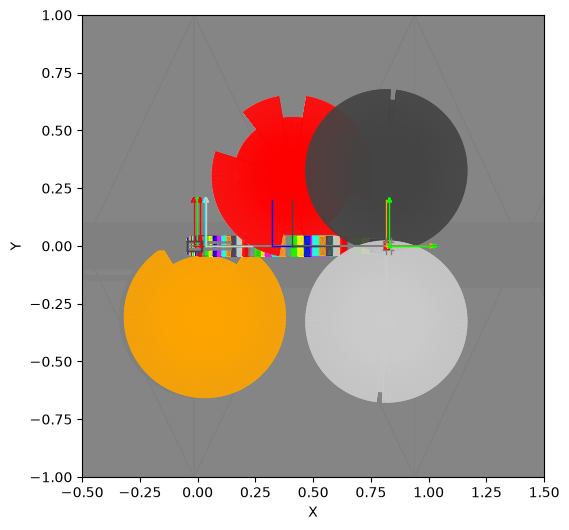

In [4]:
# z along the beam, x across it
# width and height are in pixels at 100 dpi: a figure of 16 x 4 in
with patch("matplotlib.pyplot.show"):
    mcstas_instr.show_instrument(backend="matplotlib_2d", projection="zx", width=1600, height=400)
# show_instrument returns None and has no aspect option: set it on the axes it drew
plt.gca().set_aspect("equal")
# against beam, from detector to source
# limits are in m: [min, max] of the horizontal axis, then of the vertical one
with patch("matplotlib.pyplot.show"):
    mcstas_instr.show_instrument(
        backend="matplotlib_2d", projection="xy", limits=[-0.5, 1.5, -1, 1], width=600, height=600
    )
plt.gca().set_aspect("equal")

## 3D view

In [5]:
# drag to rotate, scroll to zoom and right-drag to pan
mcstas_instr.show_instrument(backend="pythreejs", width=680, height=480)